# Serie II: regímenes de operación

**Alcance:** describir pocos perfiles de proceso mediante aprendizaje no supervisado y comprobar si representan estados sostenidos. No se desarrollan aquí anomalías, alertas ni oportunidades de eficiencia. El sensor virtual y su campeona permanecen intactos.

Se usan señales de siete familias físicas, sin la lista seleccionada por Ridge. El caudal `ZZQBCHLL`, la temperatura de salida `TE_8332A`, vibración/corriente del ventilador y señales de atemperación quedan fuera de la distancia; se conservan para caracterizar después los perfiles. Ni el caudal ni su error deciden K.

Se comparan K=2/3/4 con K-means. Interpretación, parsimonia, persistencia y estabilidad tienen prioridad; silueta e inercia son diagnósticos secundarios. K-means divide el espacio aunque haya continuidad: no se presume que existan modos discretos certificados. [Método](https://scikit-learn.org/1.6/modules/clustering.html#k-means).

In [1]:
from pathlib import Path
import hashlib
import json
import sys

import joblib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

raiz = next(p for p in [Path.cwd(), Path.cwd().parent] if (p / 'scripts/regimenes_serie2.py').exists())
sys.path.insert(0, str(raiz))
from scripts.regimenes_serie2 import FAMILIAS, ENTRADAS, PESOS, construir_vista, resumir_episodios
salida = raiz / 'outputs/regimenes'
salida.mkdir(exist_ok=True)
protegidos = [*sorted((raiz/'outputs').glob('serie2_*')), raiz/'data/raw/serie2/data.csv',
              raiz/'notebooks/07_sensor_virtual_serie2.ipynb', raiz/'scripts/modelado_serie2.py']
huellas = {str(p.relative_to(raiz)):hashlib.sha256(p.read_bytes()).hexdigest() for p in protegidos if p.is_file()}

## Vista temporal y variables

Cada intervalo de un minuto contiene las doce lecturas originales de cinco segundos y se representa con medianas. Se busca el estado sostenido; los picos originales permanecen en la fuente y en su correspondencia de etiquetas. No se excluyen observaciones ni se imputan entradas: las señales seleccionadas están completas.

Las seis presiones del hogar se sintetizan con la mediana de sus medianas temporales, como indicador numérico común, sin atribuirle una unidad calibrada. Las otras diez entradas son sensores originales. Se estandariza con los primeros cuatro días y cada familia se divide por la raíz de su número de dimensiones. Eso iguala su varianza marginal total en calibración, no su información ni su importancia física. No se afina el peso para mejorar silueta.

**Disponibilidad:** el intervalo se conoce al cerrarse. Las etiquetas asignadas a sus filas son retrospectivas; nunca se asumirán disponibles desde la primera lectura. El quinto día es proyección descriptiva con centros congelados, sin presentarlo como test virgen.

In [2]:
datos = pd.read_csv(raiz/'data/raw/serie2/data.csv', parse_dates=['date'])
vista, entradas, correspondencia = construir_vista(datos)
corte = datos.date.iloc[0] + pd.Timedelta(days=4)
calibracion = vista.disponible_desde.le(corte)
assert len(datos)==86400 and len(vista)==7200 and calibracion.sum()==5760
assert vista.filas_fuente.eq(12).all() and len(correspondencia)==len(datos)
assert not {'ZZQBCHLL.AV_0#','TE_8332A.AV_0#'}.intersection(entradas)
escalador = StandardScaler().fit(entradas.loc[calibracion])
pesos = PESOS[entradas.columns].to_numpy()
z = escalador.transform(entradas) * pesos
familias = pd.DataFrame([dict(familia=f, entrada=c, peso=float(PESOS[c])) for f,cs in FAMILIAS.items() for c in cs])
familias.to_csv(salida/'variables_y_pesos.csv', index=False)
entradas.to_csv(salida/'entradas_minuto.csv')
vista.to_csv(salida/'vista_minuto.csv')
display(familias)
print(f'Fuente {len(datos):,}; intervalos {len(vista):,}; calibración {calibracion.sum():,}; proyección {(~calibracion).sum():,}; exclusiones 0.')

,familia,entrada,peso
0,Presión de vapor,PTCA_8324.AV_0#,1.000000
1,Temperatura del hogar,TE_8313B.AV_0#,1.000000
2,Temperatura de gases,TE_8319A.AV_0#,0.707107
3,Temperatura de gases,TE_8319B.AV_0#,0.707107
4,Precalentamiento del aire,TE_8303.AV_0#,0.707107
5,Precalentamiento del aire,TE_8304.AV_0#,0.707107
6,Suministro de aire,FT_8301.AV_0#,0.707107
7,Suministro de aire,FT_8302.AV_0#,0.707107
8,Oxígeno,AIR_8301A.AV_0#,0.707107
9,Oxígeno,AIR_8301B.AV_0#,0.707107


Fuente 86,400; intervalos 7,200; calibración 5,760; proyección 1,440; exclusiones 0.


In [3]:
modelos, candidatos, centros_candidatos, semillas = {}, [], [], []
with threadpool_limits(limits=2):
    for k in [2,3,4]:
        modelo = KMeans(n_clusters=k,n_init=20,random_state=42).fit(z[calibracion])
        modelos[k] = modelo
        episodios = resumir_episodios(vista.loc[calibracion], modelo.labels_)
        tamaños = pd.Series(modelo.labels_).value_counts(normalize=True)
        valores_ari = []
        for semilla in [0,1,2,3]:
            alterno = KMeans(n_clusters=k,n_init=20,random_state=semilla).fit(z[calibracion])
            ari = adjusted_rand_score(modelo.labels_,alterno.labels_)
            valores_ari.append(ari)
            semillas.append(dict(k=k,semilla=semilla,ARI=ari))
        candidatos.append(dict(k=k,silueta_muestra_2000=silhouette_score(z[calibracion],modelo.labels_,sample_size=2000,random_state=42),
                               inercia=modelo.inertia_,menor_grupo_pct=100*tamaños.min(),episodios=len(episodios),
                               mediana_episodio_min=episodios.minutos.median(),
                               tiempo_episodios_15min_pct=100*episodios.loc[episodios.minutos.ge(15),'minutos'].sum()/calibracion.sum(),
                               ARI_min_semillas=min(valores_ari)))
        centro = entradas.loc[calibracion].assign(grupo=modelo.labels_).groupby('grupo').mean().reset_index()
        centro.insert(0,'k',k)
        centros_candidatos.append(centro)
comparacion = pd.DataFrame(candidatos)
comparacion.to_csv(salida/'comparacion_k.csv',index=False)
pd.concat(centros_candidatos).to_csv(salida/'centros_candidatos.csv',index=False)
pd.DataFrame(semillas).to_csv(salida/'estabilidad_semillas.csv',index=False)
display(comparacion.round(4))
for k in [2,3,4]:
    print('Perfiles de entradas para K=',k)
    display(pd.concat(centros_candidatos).loc[lambda t:t.k.eq(k)].round(3))

,k,silueta_muestra_2000,inercia,menor_grupo_pct,episodios,mediana_episodio_min,tiempo_episodios_15min_pct,ARI_min_semillas
0,2,0.2010,31494.5541,42.6910,145,9.0,91.6667,0.9979
1,3,0.1745,28044.3520,23.7326,431,6.0,71.4583,0.9818
2,4,0.1391,25817.8287,19.2188,619,5.0,57.9167,0.9310


Perfiles de entradas para K= 2


,k,grupo,PTCA_8324.AV_0#,TE_8313B.AV_0#,TE_8319A.AV_0#,TE_8319B.AV_0#,TE_8303.AV_0#,TE_8304.AV_0#,FT_8301.AV_0#,FT_8302.AV_0#,AIR_8301A.AV_0#,AIR_8301B.AV_0#,presion_hogar_sintesis
0,2,0,9.434,765.421,350.533,382.226,206.436,219.954,46696.325,18216.036,2.148,2.287,-149.661
1,2,1,9.445,778.777,359.600,395.056,213.048,222.937,45949.531,20452.455,2.015,2.159,-158.639


Perfiles de entradas para K= 3


,k,grupo,PTCA_8324.AV_0#,TE_8313B.AV_0#,TE_8319A.AV_0#,TE_8319B.AV_0#,TE_8303.AV_0#,TE_8304.AV_0#,FT_8301.AV_0#,FT_8302.AV_0#,AIR_8301A.AV_0#,AIR_8301B.AV_0#,presion_hogar_sintesis
0,3,0,9.427,765.853,349.736,381.100,205.696,219.500,46800.883,18145.953,2.079,2.202,-140.576
1,3,1,9.435,781.424,359.434,394.700,212.580,222.508,46068.952,20692.910,1.896,2.019,-142.061
2,3,2,9.469,768.982,357.985,392.981,212.709,223.341,45840.401,19375.683,2.370,2.574,-197.933


Perfiles de entradas para K= 4


,k,grupo,PTCA_8324.AV_0#,TE_8313B.AV_0#,TE_8319A.AV_0#,TE_8319B.AV_0#,TE_8303.AV_0#,TE_8304.AV_0#,FT_8301.AV_0#,FT_8302.AV_0#,AIR_8301A.AV_0#,AIR_8301B.AV_0#,presion_hogar_sintesis
0,4,0,9.377,774.898,355.959,390.097,210.744,222.072,45927.133,19912.232,1.923,2.044,-131.351
1,4,1,9.439,764.550,348.930,379.415,204.750,218.968,46961.626,17835.916,2.096,2.216,-144.703
2,4,2,9.481,783.199,360.818,397.003,213.585,222.967,46201.909,20845.542,1.943,2.077,-153.483
3,4,3,9.468,767.454,357.294,391.947,212.111,222.899,45878.064,19238.981,2.429,2.642,-202.581


## Elección: dos perfiles amplios

K=2 representa un contraste interpretable de estado térmico y suministro de aire, con grupos de tamaños sustanciales y periodos largos. K=3 añade un perfil de presión del hogar más negativa/oxígeno mayor, pero multiplica las transiciones y reduce persistencia; K=4 fragmenta aún más. No se observa un grupo pequeño que obligue a separar un evento como régimen propio. Se elige **K=2 por parsimonia y lectura física**, sin asumir dos modos naturales de la instalación ni escoger por el caudal.

La silueta cercana a 0.20 indica separación modesta; las fronteras tienen solapamiento. La estabilidad de semillas verifica la solución numérica, no certifica la existencia física de los regímenes.

In [4]:
k_elegido = 2
modelo = modelos[k_elegido]
# Numeración reproducible según aire secundario del centro, sin usar el caudal objetivo.
centros_originales = escalador.inverse_transform(modelo.cluster_centers_/pesos)
orden = np.argsort(centros_originales[:,ENTRADAS.index('FT_8302.AV_0#')])
renumeracion = {int(c):i+1 for i,c in enumerate(orden)}
etiquetas = np.array([renumeracion[int(c)] for c in modelo.predict(z)])
distancias = modelo.transform(z)
orden_distancias = np.sort(distancias,axis=1)
margen = (orden_distancias[:,1]-orden_distancias[:,0])/orden_distancias[:,1]
asignaciones = vista[['inicio','fin_lectura','disponible_desde','filas_fuente']].copy()
asignaciones['regimen'] = etiquetas
asignaciones['fase'] = np.where(calibracion,'Calibración días 1–4','Proyección día 5')
asignaciones['dia'] = ((vista.inicio-datos.date.iloc[0])//pd.Timedelta(days=1)).astype(int)+1
asignaciones['margen_relativo_distancias'] = margen
asignaciones['distancia_centro'] = distancias.min(axis=1)
asignaciones.to_csv(salida/'asignaciones_minuto.csv')
correspondencia['regimen'] = correspondencia.intervalo.map(asignaciones.regimen)
correspondencia['etiqueta_disponible_desde'] = correspondencia.intervalo.map(asignaciones.disponible_desde)
assert correspondencia.regimen.notna().all()
assert correspondencia.date.lt(correspondencia.etiqueta_disponible_desde).all()
correspondencia.to_csv(salida/'asignaciones_filas.csv',index=False)
episodios = resumir_episodios(vista,etiquetas)
episodios.to_csv(salida/'episodios.csv',index=False)
resumen = asignaciones.groupby('regimen').agg(minutos=('regimen','size'),margen_mediano=('margen_relativo_distancias','median'))
resumen['horas'] = resumen.minutos/60
resumen['porcentaje_tiempo'] = 100*resumen.minutos/len(vista)
duracion = episodios.groupby('regimen').minutos.agg(episodios='size',mediana_episodio_min='median',maximo_episodio_min='max')
resumen = resumen.join(duracion)
resumen.to_csv(salida/'resumen_regimenes.csv')
por_dia = pd.crosstab(asignaciones.dia,asignaciones.regimen,normalize='index')*100
por_dia.to_csv(salida/'porcentaje_por_dia.csv')
raw = datos.copy()
raw['regimen'] = correspondencia.regimen.to_numpy()
perfiles = []
for regimen,g in raw.groupby('regimen'):
    for sensor in datos.columns.drop('date'):
        s=g[sensor]
        perfiles.append(dict(regimen=regimen,sensor=sensor,mediana=s.median(),p25=s.quantile(.25),p75=s.quantile(.75),
                             media=s.mean(),registros_validos=s.notna().sum(),faltantes=s.isna().sum()))
perfil = pd.DataFrame(perfiles)
perfil.to_csv(salida/'perfiles_sensores_crudos.csv',index=False)
centros = pd.DataFrame(centros_originales[orden],columns=ENTRADAS,index=[1,2])
centros.index.name='regimen'
centros.to_csv(salida/'centros_originales.csv')
joblib.dump(dict(modelo=modelo,escalador=escalador,pesos=pesos,columnas=ENTRADAS,renumeracion=renumeracion,
                 corte_calibracion=str(corte),minutos_intervalo=1),salida/'modelo_regimenes.joblib')
display(resumen.round(3)); display(por_dia.round(2))
seleccion_perfil=['TE_8313B.AV_0#','FT_8302.AV_0#','AIR_8301A.AV_0#','AIR_8301B.AV_0#',
                  'PTCA_8324.AV_0#','ZZQBCHLL.AV_0#','TE_8332A.AV_0#']
display(perfil.loc[perfil.sensor.isin(seleccion_perfil)].pivot(index='sensor',columns='regimen',values='mediana').round(3))

,minutos,margen_mediano,horas,porcentaje_tiempo,episodios,mediana_episodio_min,maximo_episodio_min
regimen,,,,,,,
1,2707,0.330,45.117,37.597,88,9.0,282.0
2,4493,0.332,74.883,62.403,89,9.0,842.0


regimen,1,2
dia,,
1,78.06,21.94
2,28.33,71.67
3,36.25,63.75
4,28.12,71.88
5,17.22,82.78


regimen,1,2
sensor,,
AIR_8301A.AV_0#,2.12,2.02
AIR_8301B.AV_0#,2.23,2.16
FT_8302.AV_0#,18213.72,20370.17
PTCA_8324.AV_0#,9.44,9.46
TE_8313B.AV_0#,767.10,779.05
TE_8332A.AV_0#,537.44,537.88
ZZQBCHLL.AV_0#,58.37,60.77


## Sensibilidad y estabilidad

Se congela K=2 para estas comprobaciones. Se vuelve a calibrar quitando un día cada vez; se retira una familia por vez para ver dependencia del criterio físico; se prueba igual peso por columna; y se cambia de medianas de un minuto a cinco minutos. No se cambia el método para maximizar un resultado. ARI compara asignaciones y es invariante a la numeración; no mide certeza clínica/industrial. [Definición de ARI](https://scikit-learn.org/1.6/modules/generated/sklearn.metrics.adjusted_rand_score.html).

In [5]:
sensibilidades=[]
with threadpool_limits(limits=2):
    for dia in [1,2,3,4]:
        usar = calibracion & asignaciones.dia.ne(dia)
        s = StandardScaler().fit(entradas.loc[usar])
        a = KMeans(n_clusters=2,n_init=20,random_state=42).fit(s.transform(entradas.loc[usar])*pesos)
        pred = a.predict(s.transform(entradas.loc[calibracion])*pesos)
        sensibilidades.append(dict(prueba=f'Omitir día {dia}',ARI_calibracion=adjusted_rand_score(modelo.labels_,pred)))
    for familia, quitar in FAMILIAS.items():
        columnas = [c for c in ENTRADAS if c not in quitar]
        posiciones = [ENTRADAS.index(c) for c in columnas]
        a = KMeans(n_clusters=2,n_init=20,random_state=42).fit(z[calibracion][:,posiciones])
        sensibilidades.append(dict(prueba=f'Omitir familia: {familia}',ARI_calibracion=adjusted_rand_score(modelo.labels_,a.labels_)))
    a = KMeans(n_clusters=2,n_init=20,random_state=42).fit(escalador.transform(entradas.loc[calibracion]))
    sensibilidades.append(dict(prueba='Igual peso por columna',ARI_calibracion=adjusted_rand_score(modelo.labels_,a.labels_)))
    vista5,entradas5,mapa5 = construir_vista(datos,minutos=5)
    usar5 = vista5.disponible_desde.le(corte)
    s5 = StandardScaler().fit(entradas5.loc[usar5])
    a5 = KMeans(n_clusters=2,n_init=20,random_state=42).fit(s5.transform(entradas5.loc[usar5])*pesos)
    pred5 = a5.predict(s5.transform(entradas5)*pesos)
    expandida = np.repeat(pred5,5)
    assert len(expandida)==len(vista)
    sensibilidades.append(dict(prueba='Resolución de cinco minutos',ARI_calibracion=adjusted_rand_score(modelo.labels_,expandida[calibracion])))
sensibilidad = pd.DataFrame(sensibilidades)
sensibilidad.to_csv(salida/'sensibilidad.csv',index=False)
display(sensibilidad.round(4))
print('Márgenes geométricos por fase; no son probabilidades:')
display(asignaciones.groupby('fase').margen_relativo_distancias.quantile([.25,.5,.75]).unstack().round(3))
print('Distancia al centro por fase:')
display(asignaciones.groupby('fase').distancia_centro.agg(['median','mean','max']).round(3))

,prueba,ARI_calibracion
0,Omitir día 1,0.8180
1,Omitir día 2,0.9371
2,Omitir día 3,0.8665
3,Omitir día 4,0.7726
4,Omitir familia: Presión de vapor,0.9553
5,Omitir familia: Temperatura del hogar,0.6114
6,Omitir familia: Temperatura de gases,0.4029
7,Omitir familia: Precalentamiento del aire,0.6702
8,Omitir familia: Suministro de aire,0.8459
9,Omitir familia: Oxígeno,0.8998


Márgenes geométricos por fase; no son probabilidades:


,0.25,0.50,0.75
fase,,,
Calibración días 1–4,0.193,0.334,0.452
Proyección día 5,0.214,0.328,0.423


Distancia al centro por fase:


,median,mean,max
fase,,,
Calibración días 1–4,2.084,2.204,8.143
Proyección día 5,2.263,2.366,6.085


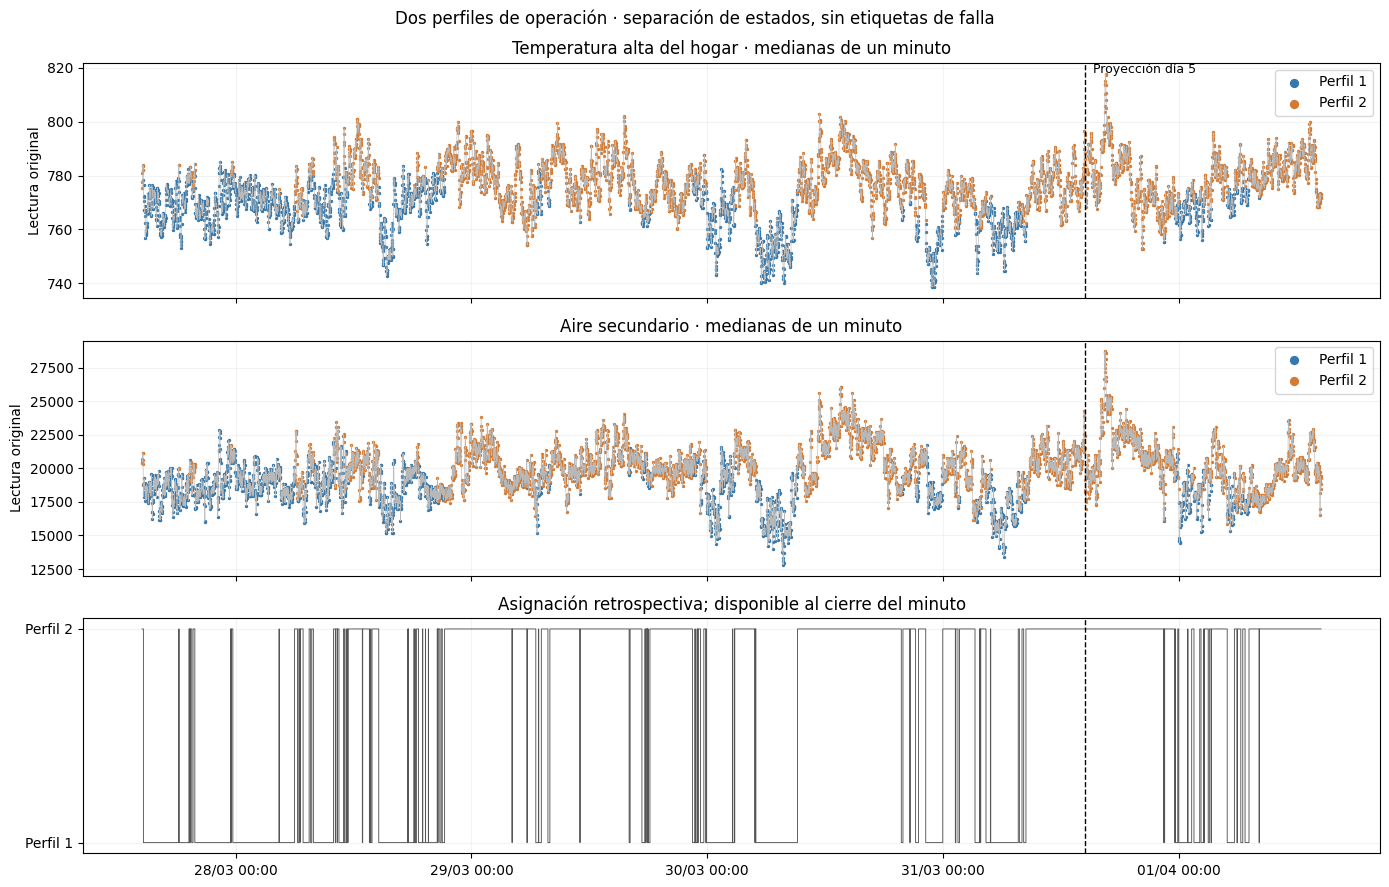

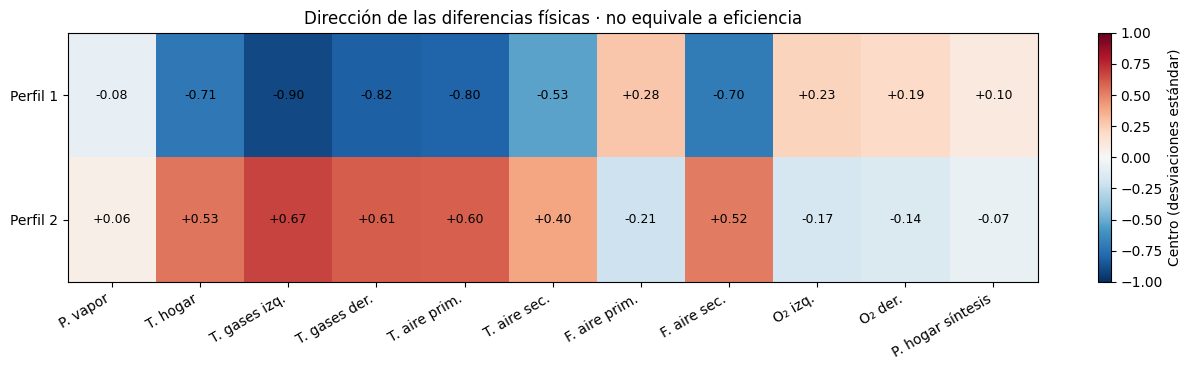

In [6]:
colores={1:'#3678AB',2:'#D47A32'}
fig,ejes=plt.subplots(3,1,figsize=(14,9),sharex=True)
for eje,sensor,titulo in zip(ejes[:2],['TE_8313B.AV_0#','FT_8302.AV_0#'],['Temperatura alta del hogar','Aire secundario']):
    eje.plot(vista.inicio,vista[sensor],color='#b8b8b8',linewidth=.45)
    for r in [1,2]:
        m=etiquetas==r
        eje.scatter(vista.loc[m,'inicio'],vista.loc[m,sensor],s=2,color=colores[r],label=f'Perfil {r}')
    eje.set_title(titulo+' · medianas de un minuto'); eje.set_ylabel('Lectura original')
    eje.legend(loc='upper right',markerscale=4)
ejes[2].step(vista.inicio,etiquetas,where='post',color='#555555',linewidth=.65)
ejes[2].set_yticks([1,2],['Perfil 1','Perfil 2']);ejes[2].set_title('Asignación retrospectiva; disponible al cierre del minuto')
for eje in ejes:
    eje.axvline(corte,color='black',linestyle='--',linewidth=1)
    eje.grid(alpha=.15)
ejes[0].text(corte,ejes[0].get_ylim()[1],'  Proyección día 5',va='top',fontsize=9)
ejes[2].xaxis.set_major_formatter(mdates.DateFormatter('%d/%m %H:%M'))
fig.suptitle('Dos perfiles de operación · separación de estados, sin etiquetas de falla')
fig.tight_layout();fig.savefig(salida/'regimenes_tiempo.png',dpi=150,bbox_inches='tight');plt.show()

fig,eje=plt.subplots(figsize=(13,3.8))
centros_z=escalador.transform(centros)
im=eje.imshow(centros_z,cmap='RdBu_r',vmin=-1,vmax=1,aspect='auto')
etiquetas_cortas=['P. vapor','T. hogar','T. gases izq.','T. gases der.','T. aire prim.','T. aire sec.',
                 'F. aire prim.','F. aire sec.','O₂ izq.','O₂ der.','P. hogar síntesis']
eje.set_xticks(range(len(ENTRADAS)),etiquetas_cortas,rotation=30,ha='right')
eje.set_yticks([0,1],['Perfil 1','Perfil 2'])
for i in range(2):
    for j in range(len(ENTRADAS)):
        eje.text(j,i,f'{centros_z[i,j]:+.2f}',ha='center',va='center',fontsize=9)
fig.colorbar(im,ax=eje,label='Centro (desviaciones estándar)')
eje.set_title('Dirección de las diferencias físicas · no equivale a eficiencia')
fig.tight_layout();fig.savefig(salida/'regimenes_perfiles.png',dpi=150,bbox_inches='tight');plt.show()

## Resultados y evaluación gerencial

Se conservan **dos perfiles amplios**, con separación modesta y solapamiento. Son una segmentación interpretable de estas señales en estos cinco días, no modos operativos certificados.

| Descripción | Perfil 1: menor estado térmico y aire secundario | Perfil 2: mayor estado térmico y aire secundario |
| --- | ---: | ---: |
| Tiempo del archivo | 37.60 % (45.12 h) | 62.40 % (74.88 h) |
| Temperatura alta del hogar, mediana | 767.10 | 779.05 |
| Aire secundario, mediana | 18,213.72 | 20,370.17 |
| Aire primario, mediana | 46,802.64 | 46,232.38 |
| Oxígeno izquierdo / derecho, medianas | 2.12 / 2.23 | 2.02 / 2.16 |
| Caudal de vapor, mediana, fuera del ajuste | 58.37 | 60.77 |
| Temperatura final de vapor, mediana, fuera del ajuste | 537.44 °C | 537.88 °C |

Las medianas se calculan sobre las filas crudas asignadas retrospectivamente a cada intervalo. Excepto TE_8332A (°C), no se atribuyen unidades físicas confirmadas a los números. El caudal y la temperatura de salida solo caracterizan después los grupos: no entran en la distancia ni deciden K.

**Lectura física.** El Perfil 2 reúne mayor temperatura del hogar, de gases y de precalentamiento del aire, junto con mayor aire secundario. El aire primario tiene una mediana algo menor; por tanto, no se interpreta como aumento uniforme de todo el aire ni se suman caudales sin confirmar sus condiciones. El oxígeno difiere poco y sus rangos se solapan. La mayor mediana de vapor acompaña este perfil, sin demostrar que elevar temperaturas o aire produzca ese efecto. La temperatura final permanece parecida entre perfiles; no se concluye que uno sea sano, anómalo o más eficiente.

**Persistencia y recurrencia.** Ambos aparecen en cada uno de los cinco bloques de 24 horas y se alternan. Hay 177 episodios y 91.86 % del tiempo pertenece a episodios de al menos quince minutos; solo 0.50 % corresponde a episodios de un minuto. La mediana por episodio es nueve minutos en ambos. Los máximos son 282 y 842 minutos. No se suavizaron etiquetas ni se eliminaron transiciones para conseguir persistencia. La duración de quince minutos es un resumen descriptivo, no una regla operativa o de alarma.

**Cambio de mezcla temporal.** El Perfil 1 ocupa 78.06 % del primer bloque y 17.22 % del quinto; el Perfil 2 llega a 82.78 % en la proyección. Esto muestra una mezcla cambiante que conviene contrastar con demanda, consignas, combustible y bitácora de operación. No permite identificar arranque, cambio de turno o causa concreta.

**Estabilidad y límites.** La silueta de K=2 es 0.201, frente a 0.174/0.139 para K=3/4. Estas alternativas generan 431/619 episodios en calibración, frente a 145 con dos grupos. La elección se apoya en lectura física y parsimonia, no en una supuesta clasificación perfecta. ARI entre semillas ≥0.998 indica reproducibilidad numérica; al omitir un día varía entre 0.773 y 0.937. Cinco minutos de agregación conserva bastante estructura (ARI 0.896), e igual peso por columna da 0.816. Omitir temperaturas de gases modifica más la partición (ARI 0.403): los perfiles dependen de representar el estado térmico. Retirar una familia cambia también la pregunta del análisis; no demuestra que esa familia deba excluirse.

**Recomendación al jefe de calderas.** Usar estos perfiles como contexto para revisar tendencias y construir después referencias de anomalía condicionadas al estado de operación. Una transición de perfil por sí sola no se tratará como falla. Validar primero su significado con consignas, carga solicitada, combustible y estados de control. No se recomienda modificar aire, presión ni temperatura con estos resultados, y no se cuantifica ahorro: faltan mediciones energéticas y costos para atribuirlo.

**Certeza.** Moderada para describir la diferencia térmica/aire en este archivo; baja para afirmar dos modos físicos exhaustivos, causas o estabilidad fuera de cinco días. El caso corresponde a una caldera de carbón, sin extrapolación automática a Santa Ana.

**Trazabilidad.** Se conservaron las 86,400 filas y su correspondencia con 7,200 intervalos, sin exclusiones. La etiqueta del minuto solo estaría disponible al cerrarse: para futuras alertas a cinco segundos se deberá usar el último intervalo cerrado o un diseño temporal distinto. No se alimentó el sensor virtual con estas etiquetas; su artefacto sigue intacto. Regímenes queda desarrollado como análisis exploratorio; los notebooks 10–12 y las conclusiones integran anomalías, oportunidades y rezagos.


**Interpretación física:** los perfiles tienen gases, caudal y señales de atemperación distintos, con temperatura final semejante. Es compatible con compensación de una salida regulada; las medianas agregadas no describen una intervención ni una comparación a igual carga. Conviene interpretar carga, estado térmico y señales de actuación conjuntamente, y comparar combustión en periodos estables semejantes. Una temperatura final estable no vuelve irrelevantes a los predictores cuya variación puede estar siendo compensada.

La [interpretación física y decisiones de Serie II](../docs/conclusiones-serie-II.md#interpretación-física-y-decisiones) reúne evidencia, hipótesis alternativas y contrastes por inciso.

In [7]:
assert set(correspondencia.fila_fuente)==set(range(len(datos)))
assert correspondencia.fila_fuente.is_unique and len(correspondencia)==86400
assert episodios.minutos.sum()==7200
assert resumen.minutos.sum()==7200 and np.isclose(resumen.porcentaje_tiempo.sum(),100)
assert escalador.n_samples_seen_==5760
assert all(hashlib.sha256((raiz/p).read_bytes()).hexdigest()==h for p,h in huellas.items())
verificacion=dict(filas_fuente=86400,intervalos_minuto=7200,intervalos_calibracion=5760,
                  intervalos_proyeccion=1440,exclusiones=0,objetivo_fuera_distancia=True,
                  temperatura_salida_fuera_distancia=True,campeona_intacta=True,k_elegido=2,
                  huellas_protegidas=huellas)
(salida/'verificacion.json').write_text(json.dumps(verificacion,ensure_ascii=False,indent=2),encoding='utf-8')
print('Conservación completa, disponibilidad al cierre y protecciones verificadas.')

Conservación completa, disponibilidad al cierre y protecciones verificadas.
